# Travelers' Inn: exploratory data analysis

**Candidate:** TODO  
**Question:** At reservation confirmation, which bookings are most likely to be cancelled or become no-shows rather than complete as occupied stays?

This notebook is a presentation plan with runnable analysis cells. Replace every **TODO interpretation** with your own evidence-based explanation, remove prompts that no longer apply, run all cells, and save the outputs before submission.

## 1. Analysis contract and prediction cutoff

The prediction is made when a reservation is confirmed. The label combines cancellation and no-show because both leave a reserved room unoccupied. Fields created at outcome time or after confirmation are not valid predictors. Reviews are post-stay and therefore excluded from modeling, although their existence and join behaviour can be audited here.

**Before continuing, explain:** who uses the score, what low-harm action they can take, why price optimisation is out of scope, and what assumptions about feature availability need stakeholder confirmation.

In [1]:
from pathlib import Path
import os
import re
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 60)

TRUE_VALUES = {"1", "true", "yes"}
FALSE_VALUES = {"0", "false", "no"}
MISSING_TOKENS = {"", "-", "null", "none", "nan", "unknown", "undefined"}


def resolve_db_path() -> Path:
    """Use an explicit environment override, then standard relative locations."""
    candidates = []
    if os.getenv("HOTEL_DB_PATH"):
        candidates.append(Path(os.environ["HOTEL_DB_PATH"]))
    candidates.extend([Path("data/hotel.db"), Path("hotel.db")])
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    locations = ", ".join(str(path) for path in candidates)
    raise FileNotFoundError(
        f"hotel.db was not found. Checked: {locations}. "
        "Place it at data/hotel.db or set HOTEL_DB_PATH."
    )


def load_bookings(db_path: Path, table: str = "bookings") -> pd.DataFrame:
    """Read the bookings table from SQLite without modifying the database."""
    if not re.fullmatch(r"[A-Za-z_][A-Za-z0-9_]*", table):
        raise ValueError(f"Unsafe table name: {table!r}")
    uri = f"file:{db_path.as_posix()}?mode=ro"
    with sqlite3.connect(uri, uri=True) as connection:
        return pd.read_sql_query(f'SELECT * FROM "{table}"', connection)


def clean_text(series: pd.Series) -> pd.Series:
    cleaned = series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    return cleaned.mask(cleaned.str.lower().isin(MISSING_TOKENS))


def normalise_category(series: pd.Series) -> pd.Series:
    return clean_text(series).str.replace(r"\s*-\s*", "-", regex=True).str.lower()


def parse_binary(series: pd.Series) -> pd.Series:
    cleaned = clean_text(series).str.lower()
    parsed = pd.Series(pd.NA, index=series.index, dtype="Int8")
    parsed.loc[cleaned.isin(TRUE_VALUES)] = 1
    parsed.loc[cleaned.isin(FALSE_VALUES)] = 0
    unknown = cleaned.notna() & parsed.isna()
    if unknown.any():
        raise ValueError(f"Unexpected target values: {sorted(cleaned.loc[unknown].unique())}")
    return parsed


def clean_bookings(raw_frame: pd.DataFrame):
    """Apply deterministic cleaning used by the EDA; no target-rate rules are learned."""
    frame = raw_frame.copy()
    if "Unnamed: 0" in frame.columns:
        frame = frame.drop(columns="Unnamed: 0")

    frame["booking_id"] = clean_text(frame["booking_id"])
    raw_rows = len(frame)
    duplicate_ids = int(frame["booking_id"].duplicated(keep="first").sum())
    frame = frame.drop_duplicates("booking_id", keep="first").copy()

    frame["target"] = parse_binary(frame["is_canceled"])
    status_target = clean_text(frame["reservation_status"]).str.lower().map(
        {"check-out": 0, "canceled": 1, "no-show": 1}
    ).astype("Int8")
    mismatches = frame["target"].notna() & status_target.notna() & frame["target"].ne(status_target)
    if mismatches.any():
        raise ValueError(f"Target/status mismatch in {int(mismatches.sum())} rows")

    numeric_columns = [
        "lead_time", "arrival_date_year", "arrival_date_week_number",
        "arrival_date_day_of_month", "stays_in_weekend_nights",
        "stays_in_week_nights", "adults", "children", "babies",
        "is_repeated_guest", "previous_cancellations",
        "previous_bookings_not_canceled", "days_in_waiting_list", "adr",
        "required_car_parking_spaces", "total_of_special_requests",
    ]
    for column in numeric_columns:
        frame[column] = pd.to_numeric(clean_text(frame[column]), errors="coerce")

    negative_lead_time = frame["lead_time"].lt(0).fillna(False)
    frame["lead_time_invalid"] = negative_lead_time.astype("int8")
    frame.loc[negative_lead_time, "lead_time"] = np.nan

    month = clean_text(frame["arrival_date_month"]).str[:3].str.title()
    date_text = (
        frame["arrival_date_year"].astype("Int64").astype("string")
        + "-" + month + "-"
        + frame["arrival_date_day_of_month"].astype("Int64").astype("string")
    )
    frame["arrival_date"] = pd.to_datetime(date_text, format="%Y-%b-%d", errors="coerce")
    if frame["arrival_date"].isna().any():
        raise ValueError(f"Unparseable arrival dates: {int(frame['arrival_date'].isna().sum())}")

    categorical_columns = [
        "hotel", "meal", "country", "market_segment", "distribution_channel",
        "reserved_room_type", "deposit_type", "agent", "company",
        "customer_type", "promo_code",
    ]
    for column in categorical_columns:
        frame[column] = normalise_category(frame[column])

    aliases = {
        "market_segment": {"onlin ta": "online ta", "online-ta": "online ta", "offline ta/t0": "offline ta/to"},
        "deposit_type": {"no depost": "no deposit", "no-deposit": "no deposit", "non-refund": "non refund"},
        "customer_type": {"transiant": "transient"},
    }
    for column, mapping in aliases.items():
        frame[column] = frame[column].replace(mapping)

    audit = {
        "raw_rows": raw_rows,
        "duplicate_booking_ids_removed": duplicate_ids,
        "clean_rows": len(frame),
    }
    return frame.reset_index(drop=True), audit


DB_PATH = resolve_db_path()
print(f"Using database: {DB_PATH.name}")

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\Singa\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Using database: hotel.db


## 2. Load and understand the database

Purpose: verify the available tables, row counts, keys, types, and join grain before choosing any analysis. Never assume the PDF schema perfectly matches the physical database.

In [2]:
with sqlite3.connect(f"file:{DB_PATH.resolve().as_posix()}?mode=ro", uri=True) as connection:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connection)
    reviews = pd.read_sql_query("SELECT * FROM reviews", connection)

raw = load_bookings(DB_PATH)
display(tables)
print(f"bookings: {len(raw):,} rows x {raw.shape[1]} columns")
print(f"reviews:  {len(reviews):,} rows x {reviews.shape[1]} columns")
display(raw.head(3))
display(pd.DataFrame({"dtype": raw.dtypes.astype(str), "non_null": raw.notna().sum(), "unique": raw.nunique(dropna=False)}))

,name
0,bookings
1,reviews


bookings: 118,549 rows x 36 columns
reviews:  17,583 rows x 3 columns


,Unnamed: 0,booking_id,client_email,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,promo_code
0,112427,SG134998,jia.ng9250@outlook.com,Airport Hotel,0,94,2025,May,20,16,0,3,2,0,0,BB,OTH,Online TA,TA/TO,0,0,0,D,D,2,No Deposit,240.0,,0,Transient,230,0,1,Check-Out,2025-05-19 00:00:00,EARLYBIRD
1,95089,SG109835,david.kumar3843@hotmail.com,Airport Hotel,1,103,2025,March,13,27,1,1,2,0,0,BB,SGP,Groups,Corporate,0,0,0,E,E,0,Non Refund,495.0,Kallang Industries,0,Transient,167.9,0,0,Canceled,2024-12-23 00:00:00,
2,78527,SG207272,mei.low3636@icloud.com,City Hotel,0,83,2025,Apr,17,23,2,3,2,0,0,BB,JPN,Online TA,TA/TO,0,0,0,A,A,1,No Deposit,9.0,,0,Transient,27.6,0,2,Check-Out,2025-04-28 00:00:00,STAY3PAY2


,dtype,non_null,unique
Unnamed: 0,object,118549,118196
booking_id,object,118549,118196
client_email,object,118549,118196
hotel,object,118549,2
is_canceled,object,118549,6
lead_time,object,118549,643
arrival_date_year,object,118549,3
arrival_date_month,object,118549,23
arrival_date_week_number,object,118549,56
arrival_date_day_of_month,object,118549,31


**Interpretation.** The physical schema does not fully match the semantic types in the brief: every booking column is stored as SQLite text, so numeric, Boolean, and date parsing must be explicit. The `Unnamed: 0` field is an exported row index rather than a business feature. There are 118,549 booking rows but 118,196 unique booking IDs and emails, indicating 353 duplicated booking records. Reviews contain 17,583 rows and 17,532 unique emails; a naive email join produces 17,632 rows, so the join is not strictly one-to-one. Reviews are also created after completed stays, making them unsuitable as predictors at booking confirmation.

In [3]:
key_audit = pd.Series({
    "booking rows": len(raw),
    "unique booking_id": raw["booking_id"].nunique(),
    "unique booking emails": raw["client_email"].nunique(),
    "review rows": len(reviews),
    "unique review emails": reviews["client_email"].nunique(),
    "rows after naive email join": len(raw.merge(reviews, on="client_email", how="inner")),
})
display(key_audit.to_frame("count"))

,count
booking rows,118549
unique booking_id,118196
unique booking emails,118196
review rows,17583
unique review emails,17532
rows after naive email join,17632


## 3. Data quality and deterministic cleaning

Purpose: quantify inconsistent encodings, blanks, category variants, duplicate IDs, and logically invalid values. Distinguish `NULL` from blank strings and placeholders. Cleaning rules must not use target rates or holdout statistics.

In [4]:
blank_like = raw.apply(lambda s: s.astype("string").str.strip().isin(["", "-", "unknown", "NULL"]).sum())
display(blank_like.sort_values(ascending=False).head(15).to_frame("blank_or_placeholder"))
for column in ["is_canceled", "arrival_date_month", "meal", "market_segment", "deposit_type", "customer_type"]:
    print(f"\n{column}")
    display(raw[column].value_counts(dropna=False).head(20).to_frame("rows"))

clean, audit = clean_bookings(raw)
display(pd.Series(audit).to_frame("value"))
numeric_audit = clean[["lead_time", "adr", "adults", "children", "babies", "stays_in_week_nights", "stays_in_weekend_nights"]].describe(percentiles=[.01, .5, .99]).T
display(numeric_audit)

,blank_or_placeholder
company,83513
promo_code,48491
agent,16281
country,956
customer_type,538
meal,510
distribution_channel,495
arrival_date_week_number,490
market_segment,473
client_email,0



is_canceled


,rows
is_canceled,
0,73910
1,42312
false,776
No,712
Yes,427
true,412



arrival_date_month


,rows
arrival_date_month,
August,13194
May,11811
March,11105
October,10633
April,10575
June,10402
September,10009
July,9415
February,7652


...

,rows
deposit_type,
No Deposit,102262
Non Refund,14148
No Depost,372
No Deposit,296
No Deposit,181
No Deposit,172
No Deposit,169
Refundable,163
NO DEPOSIT,142



customer_type


,rows
customer_type,
Transient,87865
Transient-Party,24007
Contract,3649
Group,552
,383
Transiant,286
Transient,281
Transient,266
Transient,263


,value
raw_rows,118549
duplicate_booking_ids_removed,353
clean_rows,118196


,count,mean,std,min,1%,50%,99%,max
lead_time,117846.0,105.032118,146.092042,0.0,0.0,67.0,451.0,4989.0
adr,117878.0,259.586899,253.940345,0.0,0.0,218.5,2010.6686,7108.0
adults,118196.0,1.859361,0.588057,0.0,1.0,2.0,3.0,55.0
children,118196.0,0.102685,0.395528,0.0,0.0,0.0,2.0,3.0
babies,118196.0,0.007809,0.096725,0.0,0.0,0.0,0.0,10.0
stays_in_week_nights,118196.0,2.460921,1.897867,0.0,0.0,2.0,10.0,50.0
stays_in_weekend_nights,118196.0,0.932942,0.990912,0.0,0.0,1.0,4.0,19.0


**Interpretation.** Cleaning removes 353 duplicate booking IDs, leaving 118,196 booking records. Blank strings and placeholder tokens occur in fields such as `company`, `agent`, `country`, and `promo_code`; they must be treated as missing categories rather than valid values. Boolean labels use several spellings (`0/1`, `true/false`, and `Yes/No`), months mix full names and abbreviations, and categories contain whitespace, case, and spelling variants. Negative lead time is logically impossible at confirmation and is converted to missing with an anomaly indicator. Extreme ADR, party-size, and stay-length values are retained for investigation rather than deleted using target-informed rules; robust preprocessing can reduce their influence while preserving potentially genuine cases.

## 4. Target integrity, prevalence, and business framing

Purpose: prove that the binary flag agrees with reservation status and understand whether cancellation and no-show should be combined.

reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0,0,73910,0,73910
1,41153,0,1159,42312
No,0,712,0,712
Yes,415,0,12,427
false,0,776,0,776
true,401,0,11,412
All,41969,75398,1182,118549


,status,rows,share
0,Check-Out,75398,0.636007
1,Canceled,41969,0.354022
2,No-Show,1182,0.009971


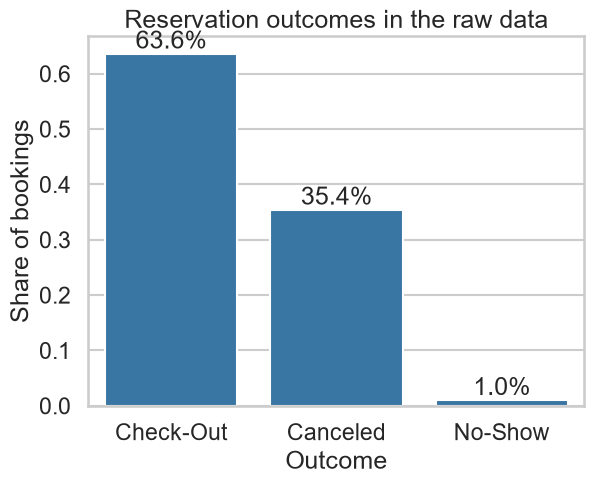

In [5]:
target_cross = pd.crosstab(raw["is_canceled"], raw["reservation_status"], margins=True)
display(target_cross)
status_counts = raw["reservation_status"].value_counts().rename_axis("status").reset_index(name="rows")
status_counts["share"] = status_counts["rows"] / status_counts["rows"].sum()
display(status_counts)
ax = sns.barplot(data=status_counts, x="status", y="share", color="#2878B5")
ax.set(title="Reservation outcomes in the raw data", xlabel="Outcome", ylabel="Share of bookings")
ax.bar_label(ax.containers[0], labels=[f"{value:.1%}" for value in status_counts["share"]])
plt.show()

**Interpretation.** The raw outcomes are 75,398 check-outs, 41,969 cancellations, and 1,182 no-shows. The normalised `is_canceled` flag agrees with `reservation_status`: both cancellations and no-shows are positive, while check-outs are negative. Combining cancellation and no-show therefore represents the shared business outcome—reserved capacity that does not become an occupied stay—and avoids building a no-show-only model from roughly 1% positive cases. The combined target is still operationally heterogeneous, so separate or hierarchical modelling remains a future option if the interventions differ.

## 5. Temporal and property patterns

Purpose: test whether prevalence changes by year, month, and hotel. This motivates a future-looking split and subgroup evaluation.

,arrival_year,hotel,rows,fallout_rate
0,2023,airport hotel,6931,0.2623
1,2023,city hotel,12262,0.412983
2,2024,airport hotel,19104,0.258899
3,2024,city hotel,39280,0.393737
4,2025,airport hotel,13173,0.307751
5,2025,city hotel,27446,0.425563


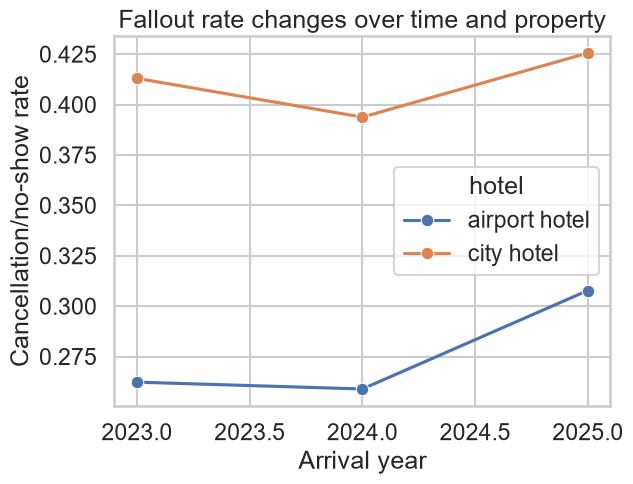

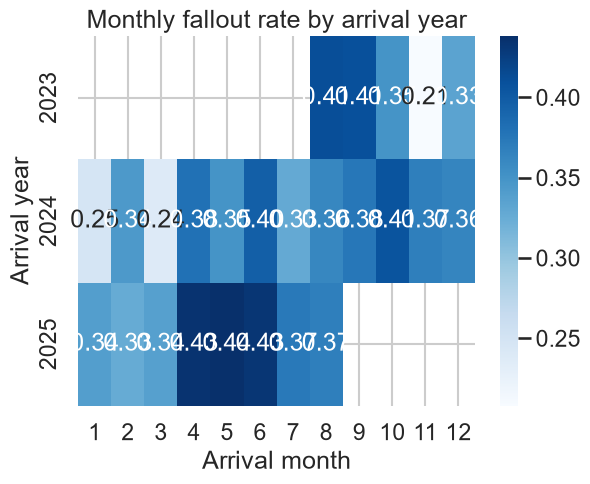

In [6]:
clean["arrival_year"] = clean["arrival_date"].dt.year
clean["arrival_month_num"] = clean["arrival_date"].dt.month
year_hotel = clean.groupby(["arrival_year", "hotel"], as_index=False).agg(rows=("target", "size"), fallout_rate=("target", "mean"))
display(year_hotel)
ax = sns.lineplot(data=year_hotel, x="arrival_year", y="fallout_rate", hue="hotel", marker="o")
ax.set(title="Fallout rate changes over time and property", xlabel="Arrival year", ylabel="Cancellation/no-show rate")
plt.show()
monthly = clean.groupby(["arrival_year", "arrival_month_num"], as_index=False)["target"].mean()
pivot = monthly.pivot(index="arrival_year", columns="arrival_month_num", values="target").astype("float64")
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Blues")
plt.title("Monthly fallout rate by arrival year")
plt.xlabel("Arrival month")
plt.ylabel("Arrival year")
plt.show()

**Interpretation.** Fallout varies materially by property and time. City Hotel's rate is approximately 41.3% in 2023, 39.4% in 2024, and 42.6% in 2025, compared with 26.2%, 25.9%, and 30.8% at Airport Hotel. Overall prevalence falls slightly from 35.9% in 2023 to 35.0% in 2024, then rises to 38.7% in 2025. This drift makes a random split optimistic because later operating conditions would leak into training. The pipeline therefore uses 2023 for training, 2024 for validation/model decisions, and 2025 as the untouched future-style holdout, with hotel/time slices monitored separately.

## 6. Booking-time feature relationships

Purpose: find actionable associations without treating them as causal. Use rates together with group sizes and inspect numeric distributions rather than only correlations.


hotel


,rows,fallout_rate
hotel,,
city hotel,78988,0.407783
airport hotel,39208,0.275913



market_segment


,rows,fallout_rate
market_segment,,
groups,18980,0.598736
online ta,56495,0.360244
offline ta/to,23422,0.346128
<NA>,475,0.336842
aviation,235,0.221277
corporate,5233,0.188037
direct,12599,0.151282
complementary,716,0.120112



distribution_channel


...


customer_type


,rows,fallout_rate
customer_type,,
transient,89069,0.402856
<NA>,535,0.366355
contract,3695,0.280379
transient-party,24331,0.240681
group,564,0.102837



promo_code


,rows,fallout_rate
promo_code,,
corp15,6823,0.3774
save10,6867,0.377312
earlybird,6993,0.372086
member,7081,0.36831
weekend,7002,0.366181
lastmin,7022,0.366135
stay3pay2,6987,0.365822
<NA>,48347,0.36085
flash,6998,0.360246


,lead_time_band,rows,fallout_rate
0,"(-inf, 7.0]",19730,0.095286
1,"(7.0, 30.0]",19764,0.263864
2,"(30.0, 90.0]",28824,0.377602
3,"(90.0, 180.0]",25673,0.446189
4,"(180.0, inf]",23855,0.564033


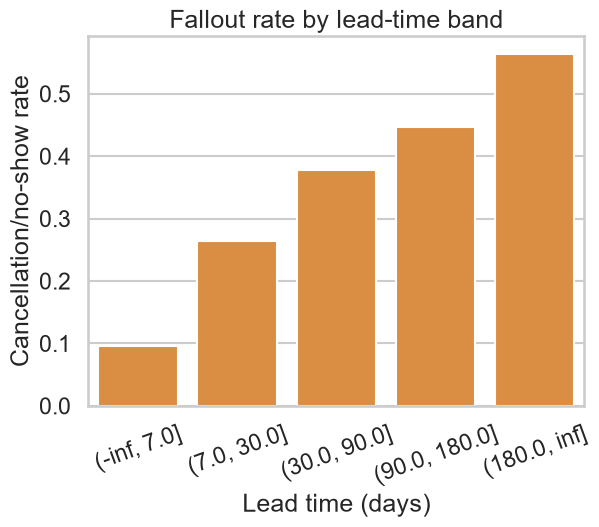

In [7]:
categorical = ["hotel", "market_segment", "distribution_channel", "deposit_type", "customer_type", "promo_code"]
for column in categorical:
    summary = clean.groupby(column, dropna=False)["target"].agg(rows="size", fallout_rate="mean").query("rows >= 100").sort_values("fallout_rate", ascending=False)
    print(f"\n{column}")
    display(summary.head(15))

plot_frame = clean.assign(lead_time_band=pd.cut(clean["lead_time"], [-np.inf, 7, 30, 90, 180, np.inf]))
lead_summary = plot_frame.groupby("lead_time_band", observed=True)["target"].agg(rows="size", fallout_rate="mean").reset_index()
display(lead_summary)
sns.barplot(data=lead_summary, x="lead_time_band", y="fallout_rate", color="#F28E2B")
plt.title("Fallout rate by lead-time band")
plt.xlabel("Lead time (days)")
plt.ylabel("Cancellation/no-show rate")
plt.xticks(rotation=20)
plt.show()

**Interpretation.** Several booking-time fields show strong associations, not causal effects. Non-refundable deposits have a 99.4% fallout rate versus 27.7% for no-deposit bookings, which may reflect policy or data-generation effects and requires stakeholder validation. Group bookings have about 59.9% fallout, compared with 15.1% for direct bookings; TA/TO distribution is also higher risk than direct distribution (40.3% versus 17.3%). City Hotel is higher risk than Airport Hotel (40.8% versus 27.6%). Lead time has a clear monotonic pattern: fallout increases from 9.5% at 0–7 days to 56.4% above 180 days. Each estimate is shown with its group size, and none should be interpreted as proof that changing the feature will change the outcome. These patterns motivate nonlinear comparison, rare-category handling, and subgroup evaluation.

## 7. Leakage audit

| Field | Decision | Reason at confirmation-time cutoff |
|---|---|---|
| `reservation_status`, `reservation_status_date` | Exclude | Direct outcome and outcome timestamp |
| `assigned_room_type` | Exclude | Actual assignment occurs at check-in |
| `booking_changes` | Exclude | Accumulates after booking creation; historical value cannot be reconstructed |
| `client_email`, `booking_id` | Exclude | PII/near-unique memorisation, not generalisable signal |
| reviews | Exclude | Written only after completed stays; structurally unavailable for fallout cases |
| `days_in_waiting_list` | Retain provisionally | Brief defines it as elapsed before confirmation |

**TODO:** Validate every retained field with a stakeholder/data-owner availability matrix. If scoring moves to seven days before arrival, rebuild historical point-in-time features rather than using final-row values.

## 8. Conclusion and pipeline decisions

The analysis supports a booking-fallout prediction problem: at reservation confirmation, estimate whether a booking will be cancelled or become a no-show rather than end in check-out. The output should be a probability and ranked risk list for low-harm actions such as reminders or reconfirmation; it should not automatically cancel, refuse, or overbook a guest.

The database contains enough positive examples for the combined task, but it requires deliberate cleaning. All booking fields arrive as text, 353 booking IDs are duplicated, Boolean and month encodings vary, categorical spelling is inconsistent, and several numeric values are logically invalid or extreme. Cleaning is deterministic and independent of target rates. Reviews are excluded because they are produced after completed stays, and `reservation_status`, `reservation_status_date`, `assigned_room_type`, and accumulated `booking_changes` are excluded from model inputs because they occur at or after the outcome/prediction cutoff. Identifiers and email addresses are also excluded to avoid memorisation and PII leakage.

The strongest descriptive signals are lead time, deposit type, market/distribution channel, and hotel. Fallout rises from 9.5% for bookings made within seven days to 56.4% above 180 days; group bookings, TA/TO bookings, non-refundable deposits, and City Hotel also have materially higher observed rates. These are associations that may be confounded by policy and customer mix, so they justify predictive features and follow-up questions—not causal interventions by themselves.

Temporal behaviour is not stable: overall fallout is 35.9% in 2023, 35.0% in 2024, and 38.7% in 2025, with persistent property differences. A chronological 2023/2024/2025 train/validation/holdout design is therefore more defensible than random splitting. Preprocessing must be fitted on training data only, with unseen-category handling and robust numeric treatment.

For modelling, regularised logistic regression provides a transparent baseline, while a random forest tests nonlinear relationships. The primary evaluation should combine average precision, recall within a fixed intervention capacity (for example the top 20% risk band), ROC-AUC, and Brier score. Any operating threshold is provisional until the business supplies intervention capacity, saved-room value, and false-alarm cost. Before deployment, the team should audit point-in-time feature availability, calibrate probabilities, check performance separately by hotel/channel/time, and validate interventions through a controlled pilot.